In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [3]:
# Carregar os dados diretamente no DataFrame
df = pd.read_csv('dados/ExpVinho.csv', sep=';')

# Criar DataFrame no formato longo
df_long = pd.DataFrame()

# Iterar pelos anos
for ano in range(1970, 2024):
    kg_col = f'{ano}'
    usd_col = f'{ano}.1'

    if kg_col in df.columns and usd_col in df.columns:
        temp_df = df[['Id', 'País', kg_col, usd_col]].copy()
        temp_df.columns = ['Id', 'País', 'Quantidade (kg)', 'Valor ($)']
        temp_df['Ano'] = ano
        df_long = pd.concat([df_long, temp_df], ignore_index=True)

df_long.head()

,Id,País,Quantidade (kg),Valor ($),Ano
0,1,Afeganistão,0,0,1970
1,2,África do Sul,0,0,1970
2,3,"Alemanha, República Democrática",0,0,1970
3,4,Angola,0,0,1970
4,5,Anguilla,0,0,1970


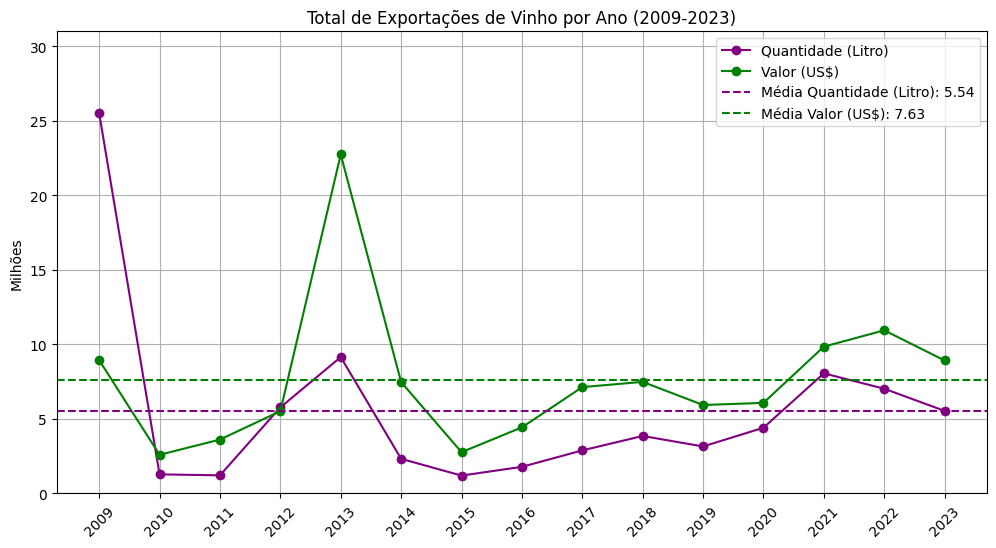

In [4]:
# Filtrar os dados para os últimos 15 anos (2009-2023)
dados_ultimos_15_anos = df_long[df_long['Ano'] >= 2009]

# Agrupar os dados por ano e somar as colunas 'Quantidade (kg)' e 'Valor ($)'
dados_agrupados = dados_ultimos_15_anos.groupby('Ano')[['Quantidade (kg)', 'Valor ($)']].sum()

# Dividir a quantidade por um milhão e o valor em dólares por um milhão
dados_agrupados['Quantidade (kg)'] = dados_agrupados['Quantidade (kg)'] / 1_000_000
dados_agrupados['Valor ($)'] = dados_agrupados['Valor ($)'] / 1_000_000

# Calcular as médias
media_quantidade = dados_agrupados['Quantidade (kg)'].mean()
media_valor = dados_agrupados['Valor ($)'].mean()

# Criar o gráfico
plt.figure(figsize=(12, 6))

# Plotando a quantidade (kg) em roxo e o valor ($) em verde
plt.plot(dados_agrupados.index, dados_agrupados['Quantidade (kg)'], marker='o', label='Quantidade (Litro)', color='purple')
plt.plot(dados_agrupados.index, dados_agrupados['Valor ($)'], marker='o', label='Valor (US$)', color='green')

# Adicionando as linhas médias
plt.axhline(media_quantidade, color='purple', linestyle='--', label=f'Média Quantidade (Litro): {media_quantidade:.2f}')
plt.axhline(media_valor, color='green', linestyle='--', label=f'Média Valor (US$): {media_valor:.2f}')

# Adicionando títulos e rótulos
plt.title('Total de Exportações de Vinho por Ano (2009-2023)')
plt.ylabel('Milhões')
plt.xlabel('')

# Ajustando os ticks do eixo X para exibir cada ano
plt.xticks(dados_agrupados.index, rotation=45)

# Definindo o limite superior do eixo Y
plt.ylim(0, 31)

# Adicionando a legenda
plt.legend()

# Exibindo o gráfico
plt.grid(True)
plt.show()

In [5]:
# Filtrar dados para os últimos 15 anos (2009-2023)
df_recent = df_long[df_long['Ano'] >= 2009]

# Somar a quantidade exportada por país
df_summary = df_recent.groupby('País').agg({'Quantidade (kg)': 'sum'}).reset_index()

# Ordenar os países pela quantidade exportada e pegar os 15 maiores
top_15_exportadores = df_summary.sort_values('Quantidade (kg)', ascending=False).head(15)

# Dividir os valores por 1 milhão
top_15_exportadores['Quantidade (kg)'] = top_15_exportadores['Quantidade (kg)'] / 1_000_000


<ipython-input-6-9b706451b62d>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  bar_plot = sns.barplot(data=top_15_exportadores, x='Quantidade (kg)', y='País', palette=['purple']*15)


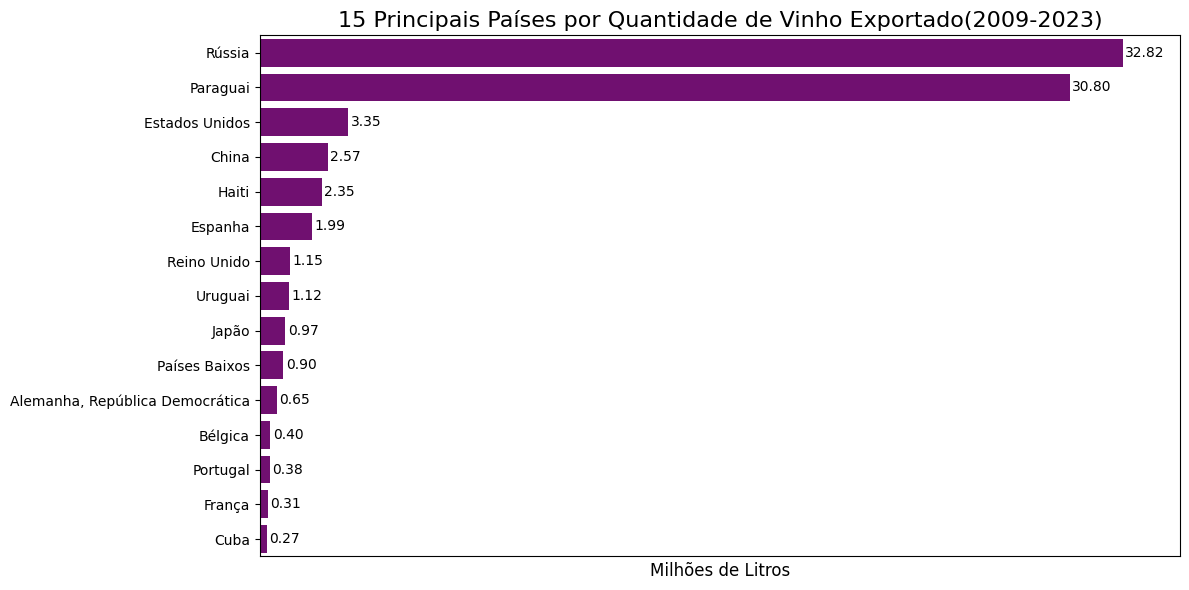

In [6]:
# Gráfico de barras laterais com colunas roxas
plt.figure(figsize=(12, 6))  # Ajustando o tamanho da figura
bar_plot = sns.barplot(data=top_15_exportadores, x='Quantidade (kg)', y='País', palette=['purple']*15)

# Adicionando o título e rótulos
plt.title('15 Principais Países por Quantidade de Vinho Exportado(2009-2023)', fontsize=16)
plt.xlabel('Milhões de Litros', fontsize=12)
plt.ylabel('')

# Adicionando os rótulos ao lado das barras
for index, value in enumerate(top_15_exportadores['Quantidade (kg)']):
    bar_plot.text(value + 0.1, index, f'{value:.2f}', color='black', va='center')

# Definir o limite máximo do eixo x
plt.xlim(0, 35)

# Remover os rótulos do eixo x (valores de quantidade)
plt.xticks([])

plt.tight_layout()
plt.show()


<ipython-input-7-948a874db166>:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  bar_plot_value = sns.barplot(data=top_15_exportadores_value, x='Valor ($)', y='País', palette=['green']*15)


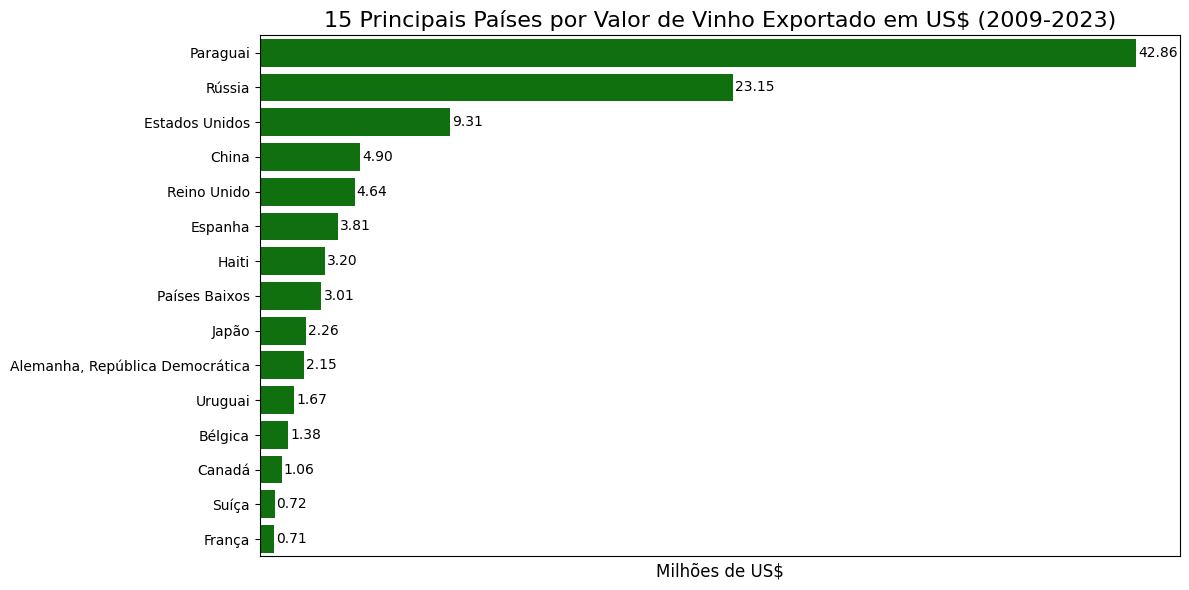

In [7]:
# Somar o valor exportado por país (em dólares)
df_summary_value = df_recent.groupby('País').agg({'Valor ($)': 'sum'}).reset_index()

# Ordenar os países pelo valor exportado e pegar os 15 maiores
top_15_exportadores_value = df_summary_value.sort_values('Valor ($)', ascending=False).head(15)

# Dividir os valores por 1 milhão (para facilitar a visualização)
top_15_exportadores_value['Valor ($)'] = top_15_exportadores_value['Valor ($)'] / 1_000_000

# Gráfico de barras laterais para o valor exportado
plt.figure(figsize=(12, 6))  # Ajustando o tamanho da figura
bar_plot_value = sns.barplot(data=top_15_exportadores_value, x='Valor ($)', y='País', palette=['green']*15)

# Adicionando o título e rótulos
plt.title('15 Principais Países por Valor de Vinho Exportado em US$ (2009-2023)', fontsize=16)
plt.xlabel('Milhões de US$', fontsize=12)
plt.ylabel('')

# Adicionando os rótulos ao lado das barras
for index, value in enumerate(top_15_exportadores_value['Valor ($)']):
    bar_plot_value.text(value + 0.1, index, f'{value:.2f}', color='black', va='center')

# Definir o limite máximo do eixo x
plt.xlim(0, 45)

# Remover os rótulos do eixo x (valores de quantidade)
plt.xticks([])

# Ajustar o layout para que tudo fique visível
plt.tight_layout()
plt.show()


<ipython-input-8-e7ddcf16c3b0>:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dados_ultimos_15_anos_russia['Quantidade (kg)'] = dados_ultimos_15_anos_russia['Quantidade (kg)'] / 1_000_000
<ipython-input-8-e7ddcf16c3b0>:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dados_ultimos_15_anos_russia['Valor ($)'] = dados_ultimos_15_anos_russia['Valor ($)'] / 1_000_000


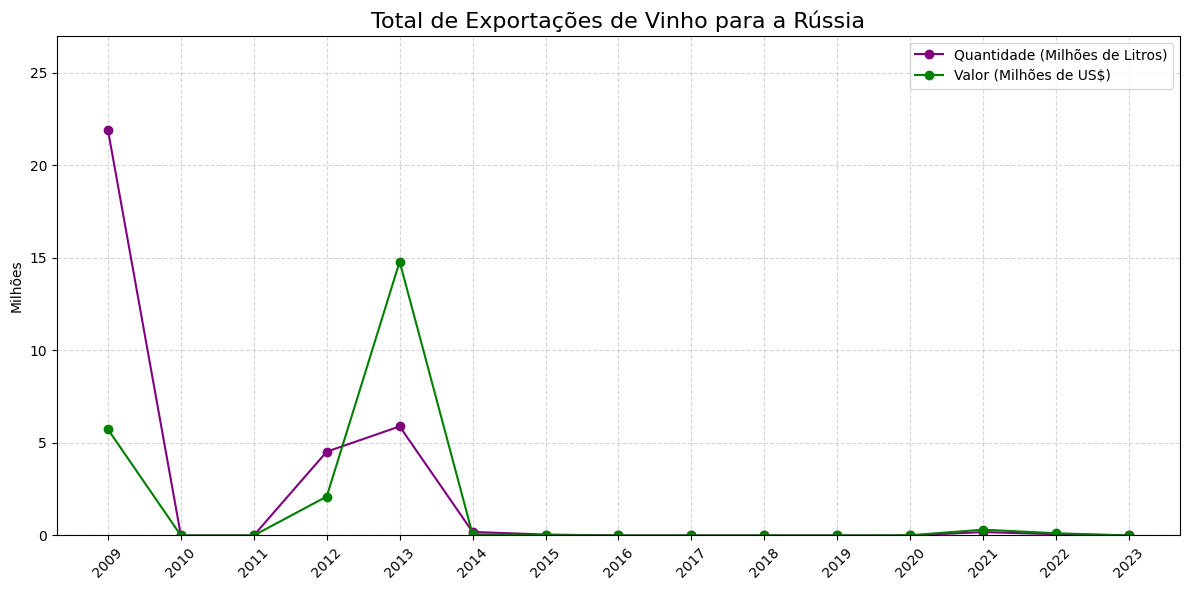

In [8]:
# Filtrar os dados para a Rússia (últimos 15 anos)
dados_ultimos_15_anos_russia = df_long[(df_long['Ano'] >= 2009) & (df_long['País'] == 'Rússia')]

# Dividir a quantidade e o valor por 1 milhão
dados_ultimos_15_anos_russia['Quantidade (kg)'] = dados_ultimos_15_anos_russia['Quantidade (kg)'] / 1_000_000
dados_ultimos_15_anos_russia['Valor ($)'] = dados_ultimos_15_anos_russia['Valor ($)'] / 1_000_000

# Criar o gráfico
plt.figure(figsize=(12, 6))

# Plotando a quantidade (litros) em roxo e o valor ($) em verde
plt.plot(dados_ultimos_15_anos_russia['Ano'], dados_ultimos_15_anos_russia['Quantidade (kg)'], marker='o', label='Quantidade (Milhões de Litros)', color='purple')
plt.plot(dados_ultimos_15_anos_russia['Ano'], dados_ultimos_15_anos_russia['Valor ($)'], marker='o', label='Valor (Milhões de US$)', color='green')

# Adicionando título e rótulos
plt.title('Total de Exportações de Vinho para a Rússia', fontsize=16)
plt.ylabel('Milhões')

# Ajustando os ticks do eixo X para exibir cada ano
plt.xticks(dados_ultimos_15_anos_russia['Ano'], rotation=45)

# Adicionando a legenda
plt.legend()

# Adicionando grade
plt.grid(True, linestyle='--', alpha=0.5)

# Ajustar o limite do eixo Y
plt.ylim(0, 27)

# Ajustar o layout
plt.tight_layout()
plt.show()



<ipython-input-9-2237b3efeb53>:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dados_ultimos_15_anos_paraguai['Quantidade (kg)'] = dados_ultimos_15_anos_paraguai['Quantidade (kg)'] / 1_000_000
<ipython-input-9-2237b3efeb53>:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dados_ultimos_15_anos_paraguai['Valor ($)'] = dados_ultimos_15_anos_paraguai['Valor ($)'] / 1_000_000


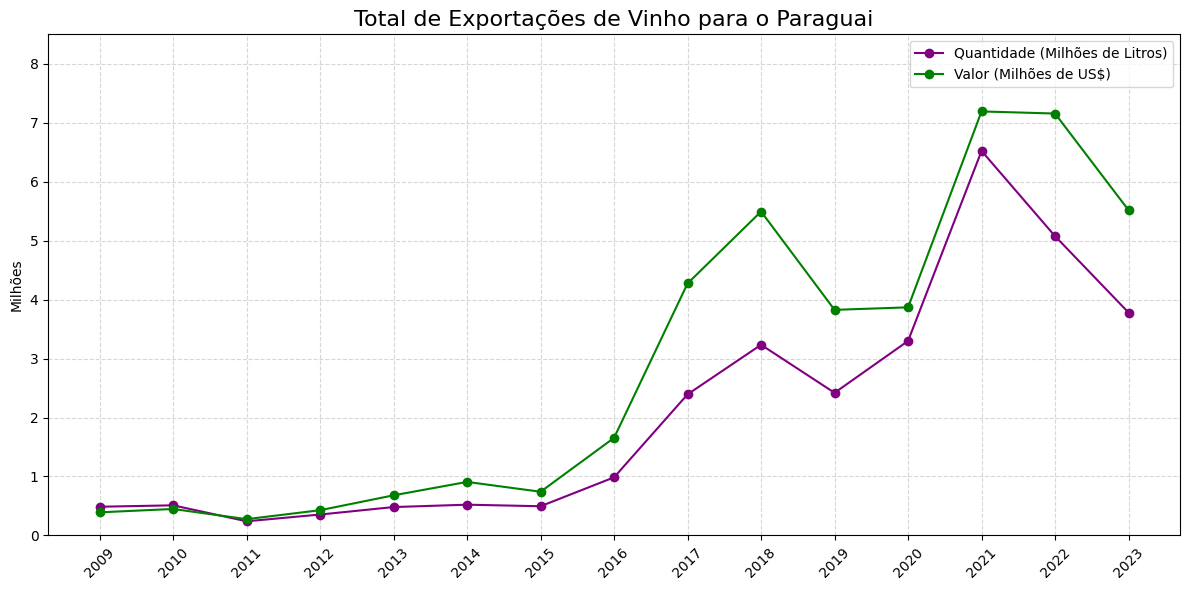

In [9]:
# Filtrar os dados para o Paraguai (últimos 15 anos)
dados_ultimos_15_anos_paraguai = df_long[(df_long['Ano'] >= 2009) & (df_long['País'] == 'Paraguai')]

# Dividir a quantidade e o valor por 1 milhão
dados_ultimos_15_anos_paraguai['Quantidade (kg)'] = dados_ultimos_15_anos_paraguai['Quantidade (kg)'] / 1_000_000
dados_ultimos_15_anos_paraguai['Valor ($)'] = dados_ultimos_15_anos_paraguai['Valor ($)'] / 1_000_000

# Criar o gráfico
plt.figure(figsize=(12, 6))

# Plotando a quantidade (litros) em roxo e o valor ($) em verde
plt.plot(dados_ultimos_15_anos_paraguai['Ano'], dados_ultimos_15_anos_paraguai['Quantidade (kg)'], marker='o', label='Quantidade (Milhões de Litros)', color='purple')
plt.plot(dados_ultimos_15_anos_paraguai['Ano'], dados_ultimos_15_anos_paraguai['Valor ($)'], marker='o', label='Valor (Milhões de US$)', color='green')

# Adicionando título e rótulos
plt.title('Total de Exportações de Vinho para o Paraguai', fontsize=16)
plt.ylabel('Milhões')

# Ajustando os ticks do eixo X para exibir cada ano
plt.xticks(dados_ultimos_15_anos_paraguai['Ano'], rotation=45)

# Adicionando a legenda
plt.legend()

# Adicionando grade
plt.grid(True, linestyle='--', alpha=0.5)

# Ajustar o limite do eixo Y
plt.ylim(0, 8.5)

# Ajustar o layout
plt.tight_layout()
plt.show()

<ipython-input-10-8e2ad5a69b8a>:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dados_ultimos_15_anos_eua['Quantidade (kg)'] = dados_ultimos_15_anos_eua['Quantidade (kg)'] / 1_000_000
<ipython-input-10-8e2ad5a69b8a>:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dados_ultimos_15_anos_eua['Valor ($)'] = dados_ultimos_15_anos_eua['Valor ($)'] / 1_000_000


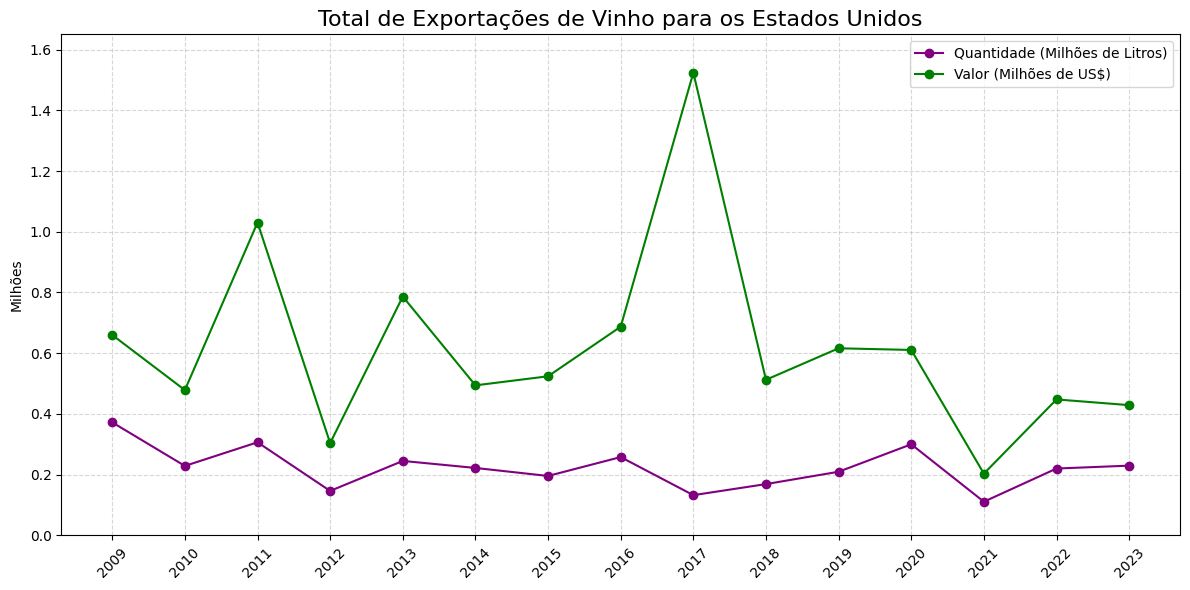

In [10]:
# Filtrar os dados para os Estados Unidos (últimos 15 anos)
dados_ultimos_15_anos_eua = df_long[(df_long['Ano'] >= 2009) & (df_long['País'] == 'Estados Unidos')]

# Dividir a quantidade e o valor por 1 milhão
dados_ultimos_15_anos_eua['Quantidade (kg)'] = dados_ultimos_15_anos_eua['Quantidade (kg)'] / 1_000_000
dados_ultimos_15_anos_eua['Valor ($)'] = dados_ultimos_15_anos_eua['Valor ($)'] / 1_000_000

# Criar o gráfico
plt.figure(figsize=(12, 6))

# Plotando a quantidade (litros) em roxo e o valor ($) em verde
plt.plot(dados_ultimos_15_anos_eua['Ano'], dados_ultimos_15_anos_eua['Quantidade (kg)'], marker='o', label='Quantidade (Milhões de Litros)', color='purple')
plt.plot(dados_ultimos_15_anos_eua['Ano'], dados_ultimos_15_anos_eua['Valor ($)'], marker='o', label='Valor (Milhões de US$)', color='green')

# Adicionando título e rótulos
plt.title('Total de Exportações de Vinho para os Estados Unidos', fontsize=16)
plt.ylabel('Milhões')

# Ajustando os ticks do eixo X para exibir cada ano
plt.xticks(dados_ultimos_15_anos_eua['Ano'], rotation=45)

# Adicionando a legenda
plt.legend()

# Adicionando grade
plt.grid(True, linestyle='--', alpha=0.5)

# Ajustar o limite do eixo Y
plt.ylim(0, 1.65)

# Ajustar o layout
plt.tight_layout()
plt.show()

<ipython-input-11-306e6ae6c735>:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dados_ultimos_15_anos_china['Quantidade (kg)'] = dados_ultimos_15_anos_china['Quantidade (kg)'] / 1_000_000
<ipython-input-11-306e6ae6c735>:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dados_ultimos_15_anos_china['Valor ($)'] = dados_ultimos_15_anos_china['Valor ($)'] / 1_000_000


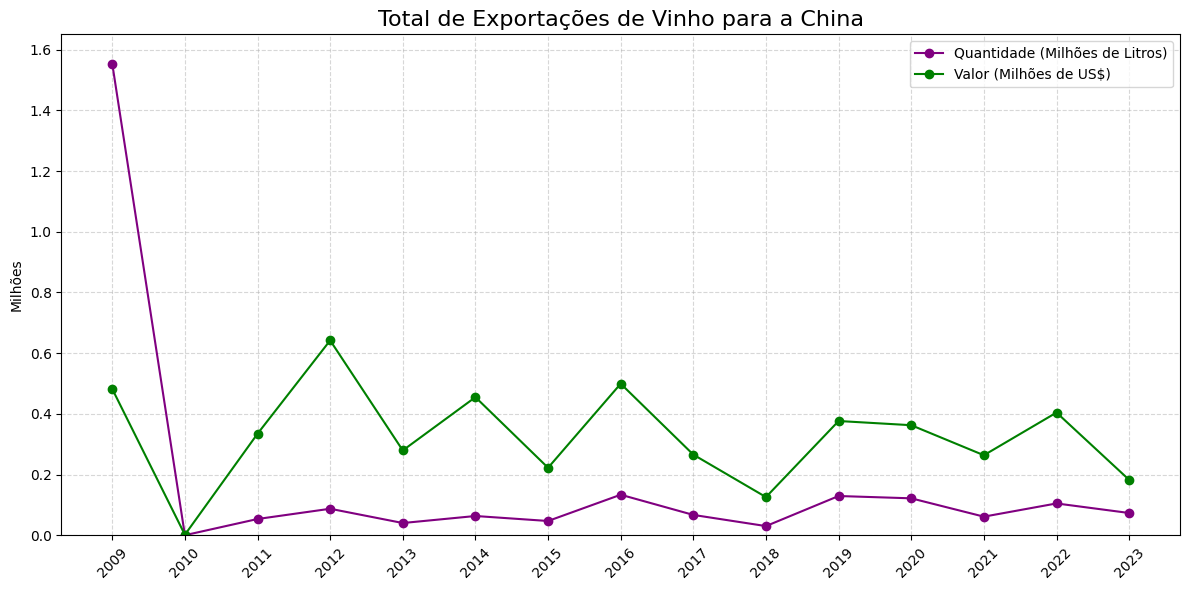

In [11]:
# Filtrar os dados para a China (últimos 15 anos)
dados_ultimos_15_anos_china = df_long[(df_long['Ano'] >= 2009) & (df_long['País'] == 'China')]

# Dividir a quantidade e o valor por 1 milhão
dados_ultimos_15_anos_china['Quantidade (kg)'] = dados_ultimos_15_anos_china['Quantidade (kg)'] / 1_000_000
dados_ultimos_15_anos_china['Valor ($)'] = dados_ultimos_15_anos_china['Valor ($)'] / 1_000_000

# Criar o gráfico
plt.figure(figsize=(12, 6))

# Plotando a quantidade (litros) em roxo e o valor ($) em verde
plt.plot(dados_ultimos_15_anos_china['Ano'], dados_ultimos_15_anos_china['Quantidade (kg)'], marker='o', label='Quantidade (Milhões de Litros)', color='purple')
plt.plot(dados_ultimos_15_anos_china['Ano'], dados_ultimos_15_anos_china['Valor ($)'], marker='o', label='Valor (Milhões de US$)', color='green')

# Adicionando título e rótulos
plt.title('Total de Exportações de Vinho para a China', fontsize=16)
plt.ylabel('Milhões')

# Ajustando os ticks do eixo X para exibir cada ano
plt.xticks(dados_ultimos_15_anos_china['Ano'], rotation=45)

# Adicionando a legenda
plt.legend()

# Adicionando grade
plt.grid(True, linestyle='--', alpha=0.5)

# Ajustar o limite do eixo Y
plt.ylim(0, 1.65)

# Ajustar o layout
plt.tight_layout()
plt.show()

<ipython-input-12-5acac934d9d7>:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dados_ultimos_15_anos_reino_unido['Quantidade (kg)'] = dados_ultimos_15_anos_reino_unido['Quantidade (kg)'] / 1_000_000
<ipython-input-12-5acac934d9d7>:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dados_ultimos_15_anos_reino_unido['Valor ($)'] = dados_ultimos_15_anos_reino_unido['Valor ($)'] / 1_000_000


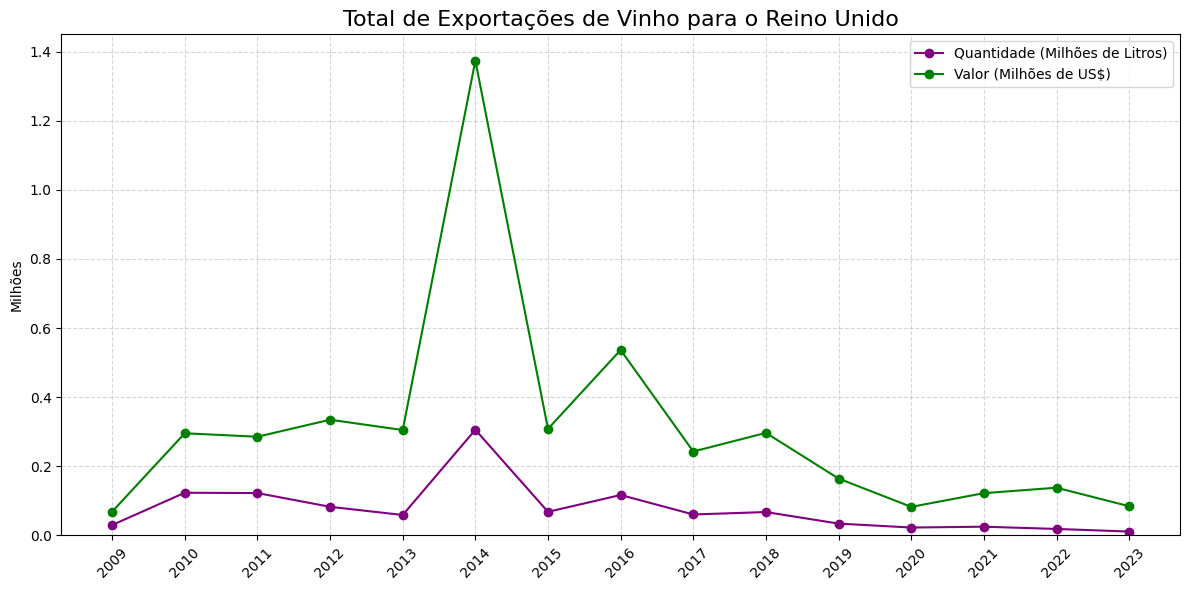

In [12]:
# Filtrar os dados para o Reino Unido (últimos 15 anos)
dados_ultimos_15_anos_reino_unido = df_long[(df_long['Ano'] >= 2009) & (df_long['País'] == 'Reino Unido')]

# Dividir a quantidade e o valor por 1 milhão
dados_ultimos_15_anos_reino_unido['Quantidade (kg)'] = dados_ultimos_15_anos_reino_unido['Quantidade (kg)'] / 1_000_000
dados_ultimos_15_anos_reino_unido['Valor ($)'] = dados_ultimos_15_anos_reino_unido['Valor ($)'] / 1_000_000

# Criar o gráfico
plt.figure(figsize=(12, 6))

# Plotando a quantidade (litros) em roxo e o valor ($) em verde
plt.plot(dados_ultimos_15_anos_reino_unido['Ano'], dados_ultimos_15_anos_reino_unido['Quantidade (kg)'], marker='o', label='Quantidade (Milhões de Litros)', color='purple')
plt.plot(dados_ultimos_15_anos_reino_unido['Ano'], dados_ultimos_15_anos_reino_unido['Valor ($)'], marker='o', label='Valor (Milhões de US$)', color='green')

# Adicionando título e rótulos
plt.title('Total de Exportações de Vinho para o Reino Unido', fontsize=16)
plt.ylabel('Milhões')

# Ajustando os ticks do eixo X para exibir cada ano
plt.xticks(dados_ultimos_15_anos_reino_unido['Ano'], rotation=45)

# Adicionando a legenda
plt.legend()

# Adicionando grade
plt.grid(True, linestyle='--', alpha=0.5)

# Ajustar o limite do eixo Y
plt.ylim(0, 1.45)

# Ajustar o layout
plt.tight_layout()
plt.show()

<ipython-input-13-3c02b89ab91e>:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dados_ultimos_15_anos_espanha['Quantidade (kg)'] = dados_ultimos_15_anos_espanha['Quantidade (kg)'] / 1_000_000
<ipython-input-13-3c02b89ab91e>:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dados_ultimos_15_anos_espanha['Valor ($)'] = dados_ultimos_15_anos_espanha['Valor ($)'] / 1_000_000


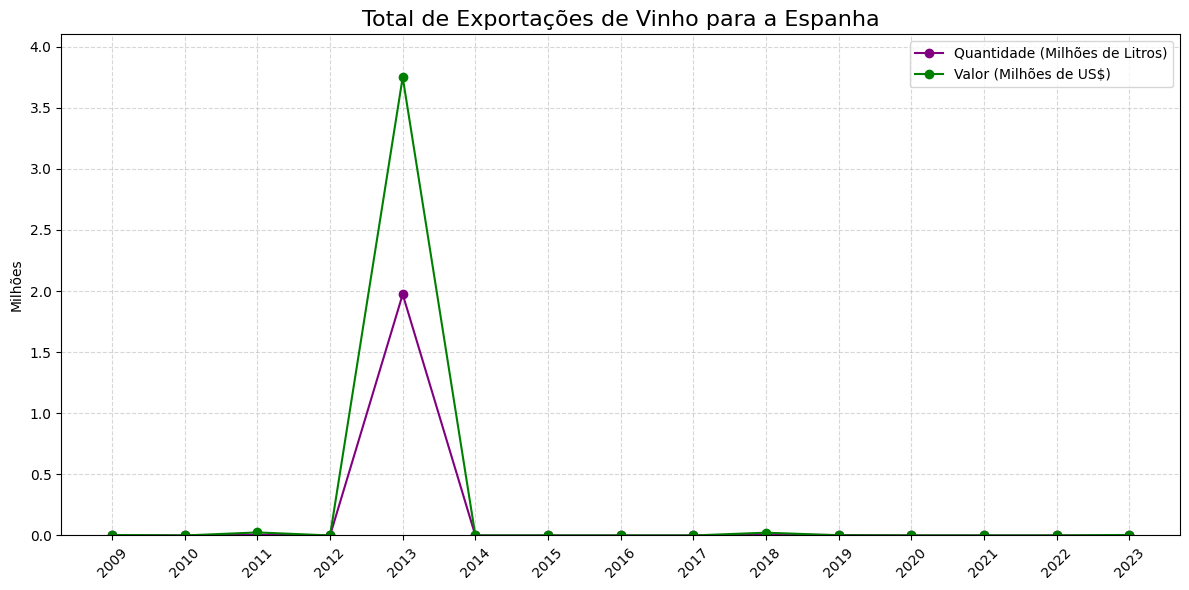

In [13]:
# Filtrar os dados para a Espanha (últimos 15 anos)
dados_ultimos_15_anos_espanha = df_long[(df_long['Ano'] >= 2009) & (df_long['País'] == 'Espanha')]

# Dividir a quantidade e o valor por 1 milhão
dados_ultimos_15_anos_espanha['Quantidade (kg)'] = dados_ultimos_15_anos_espanha['Quantidade (kg)'] / 1_000_000
dados_ultimos_15_anos_espanha['Valor ($)'] = dados_ultimos_15_anos_espanha['Valor ($)'] / 1_000_000

# Criar o gráfico
plt.figure(figsize=(12, 6))

# Plotando a quantidade (litros) em roxo e o valor ($) em verde
plt.plot(dados_ultimos_15_anos_espanha['Ano'], dados_ultimos_15_anos_espanha['Quantidade (kg)'], marker='o', label='Quantidade (Milhões de Litros)', color='purple')
plt.plot(dados_ultimos_15_anos_espanha['Ano'], dados_ultimos_15_anos_espanha['Valor ($)'], marker='o', label='Valor (Milhões de US$)', color='green')

# Adicionando título e rótulos
plt.title('Total de Exportações de Vinho para a Espanha', fontsize=16)
plt.ylabel('Milhões')

# Ajustando os ticks do eixo X para exibir cada ano
plt.xticks(dados_ultimos_15_anos_espanha['Ano'], rotation=45)

# Adicionando a legenda
plt.legend()

# Adicionando grade
plt.grid(True, linestyle='--', alpha=0.5)

# Ajustar o limite do eixo Y
plt.ylim(0, 4.1)

# Ajustar o layout
plt.tight_layout()
plt.show()


<ipython-input-14-1c0d143f21fb>:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dados_ultimos_15_anos_haiti['Quantidade (kg)'] = dados_ultimos_15_anos_haiti['Quantidade (kg)'] / 1_000_000
<ipython-input-14-1c0d143f21fb>:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dados_ultimos_15_anos_haiti['Valor ($)'] = dados_ultimos_15_anos_haiti['Valor ($)'] / 1_000_000


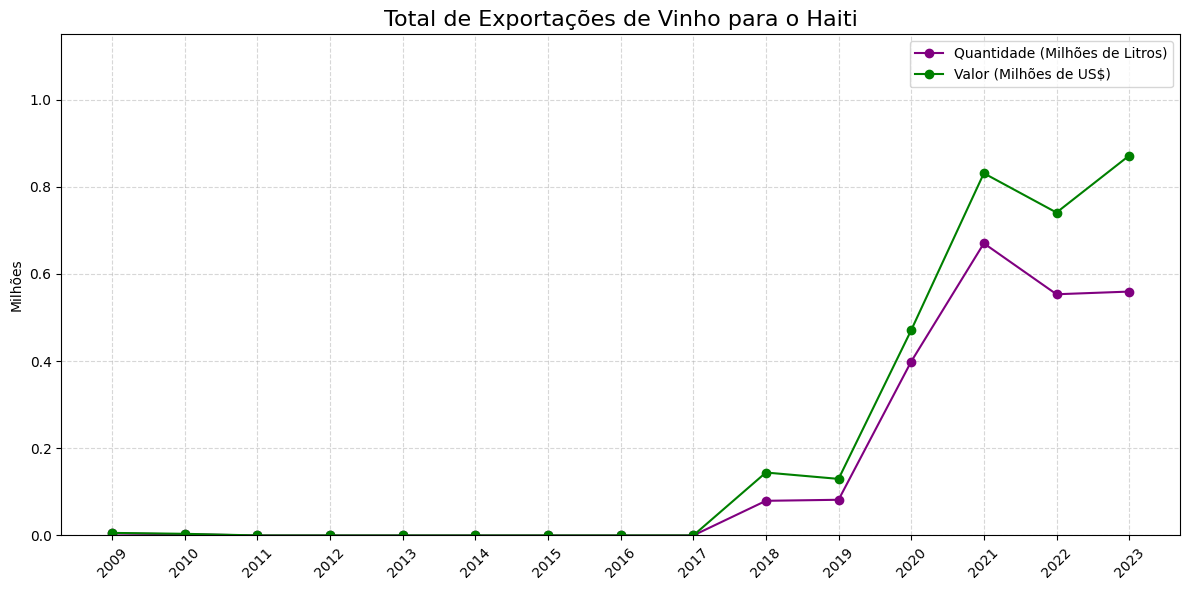

In [14]:
# Filtrar os dados para o Haiti (últimos 15 anos)
dados_ultimos_15_anos_haiti = df_long[(df_long['Ano'] >= 2009) & (df_long['País'] == 'Haiti')]

# Dividir a quantidade e o valor por 1 milhão
dados_ultimos_15_anos_haiti['Quantidade (kg)'] = dados_ultimos_15_anos_haiti['Quantidade (kg)'] / 1_000_000
dados_ultimos_15_anos_haiti['Valor ($)'] = dados_ultimos_15_anos_haiti['Valor ($)'] / 1_000_000

# Criar o gráfico
plt.figure(figsize=(12, 6))

# Plotando a quantidade (litros) em roxo e o valor ($) em verde
plt.plot(dados_ultimos_15_anos_haiti['Ano'], dados_ultimos_15_anos_haiti['Quantidade (kg)'], marker='o', label='Quantidade (Milhões de Litros)', color='purple')
plt.plot(dados_ultimos_15_anos_haiti['Ano'], dados_ultimos_15_anos_haiti['Valor ($)'], marker='o', label='Valor (Milhões de US$)', color='green')

# Adicionando título e rótulos
plt.title('Total de Exportações de Vinho para o Haiti', fontsize=16)
plt.ylabel('Milhões')

# Ajustando os ticks do eixo X para exibir cada ano
plt.xticks(dados_ultimos_15_anos_haiti['Ano'], rotation=45)

# Adicionando a legenda
plt.legend()

# Adicionando grade
plt.grid(True, linestyle='--', alpha=0.5)

# Ajustar o limite do eixo Y
plt.ylim(0, 1.15)

# Ajustar o layout
plt.tight_layout()
plt.show()

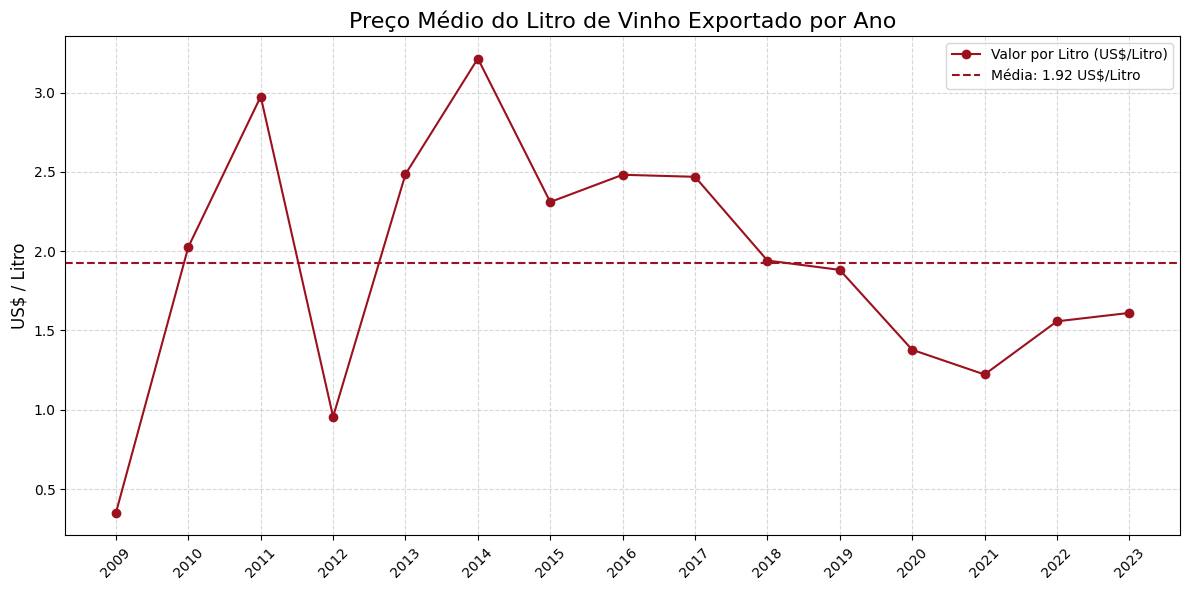

In [15]:
# Filtrar os dados para os últimos 15 anos (2009-2023)
df_recent_15 = df_long[df_long['Ano'] >= 2009]

# Agrupar os dados por ano, somando a quantidade e o valor exportado
df_yearly_15 = df_recent_15.groupby('Ano').agg({
    'Quantidade (kg)': 'sum',
    'Valor ($)': 'sum'
}).reset_index()

# Calcular o valor médio por litro (assumindo que 1 kg = 1 litro)
df_yearly_15['Valor por Litro (US$)'] = df_yearly_15['Valor ($)'] / df_yearly_15['Quantidade (kg)']

# Remover anos com possíveis divisões inválidas
df_yearly_15 = df_yearly_15.replace([np.inf, -np.inf], np.nan).dropna(subset=['Valor por Litro (US$)'])

# Calcular a média do valor por litro
media_valor_litro = df_yearly_15['Valor por Litro (US$)'].mean()

# Criar o gráfico de linhas
plt.figure(figsize=(12,6))
plt.plot(df_yearly_15['Ano'], df_yearly_15['Valor por Litro (US$)'],
         marker='o', color='#9B111E', linestyle='-', label='Valor por Litro (US$/Litro)')

# Adicionando linha média pontilhada
plt.axhline(media_valor_litro, color='#9B111E', linestyle='--', label=f'Média: {media_valor_litro:.2f} US$/Litro')

# Adicionando título e rótulos
plt.title('Preço Médio do Litro de Vinho Exportado por Ano', fontsize=16)
plt.xlabel('')
plt.ylabel('US$ / Litro', fontsize=12)

# Ajustar os ticks do eixo X para exibir cada ano
plt.xticks(df_yearly_15['Ano'], rotation=45)

# Adicionando legenda
plt.legend()

# Adicionando grade
plt.grid(True, linestyle='--', alpha=0.5)

# Ajustar o layout
plt.tight_layout()
plt.show()

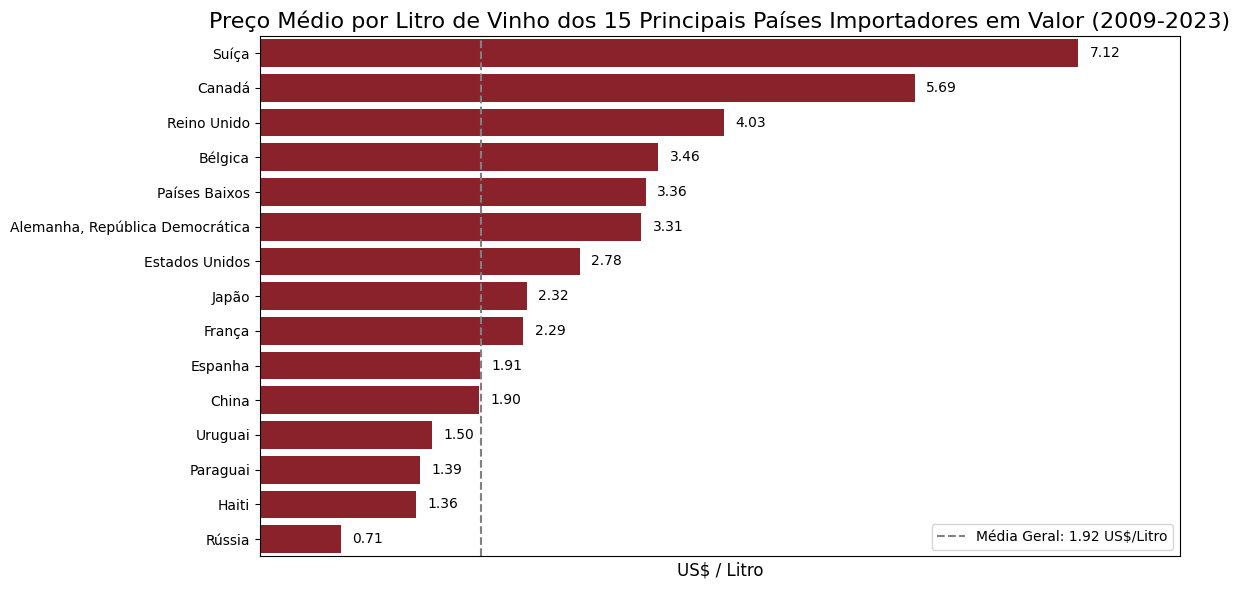

In [16]:
# Somar o valor exportado e a quantidade exportada por país
df_summary = df_recent.groupby('País').agg({
    'Quantidade (kg)': 'sum',
    'Valor ($)': 'sum'
}).reset_index()

# Ordenar os países pelo valor exportado (do maior para o menor)
top_15_exportadores_value = df_summary.sort_values('Valor ($)', ascending=False).head(15)

# Calcular a razão entre o valor e a quantidade
top_15_exportadores_value['Razão (US$/Kg)'] = top_15_exportadores_value['Valor ($)'] / top_15_exportadores_value['Quantidade (kg)']

# Ordenar os 15 principais países pela razão (do maior para o menor)
top_15_by_ratio = top_15_exportadores_value.sort_values('Razão (US$/Kg)', ascending=False)

# Gráfico de barras laterais para a razão
plt.figure(figsize=(12, 6))  # Ajustando o tamanho da figura
bar_plot_ratio = sns.barplot(data=top_15_by_ratio, x='Razão (US$/Kg)', y='País', color='#9B111E')

# Adicionando linha média
plt.axvline(media_valor_litro, color='gray', linestyle='--', label=f'Média Geral: {media_valor_litro:.2f} US$/Litro')

# Adicionando legenda
plt.legend()

# Adicionando o título e rótulos
plt.title('Preço Médio por Litro de Vinho dos 15 Principais Países Importadores em Valor (2009-2023)', fontsize=16)
plt.xlabel('US$ / Litro', fontsize=12)
plt.ylabel('')

# Adicionando os rótulos ao lado das barras
for index, value in enumerate(top_15_by_ratio['Razão (US$/Kg)']):
    bar_plot_ratio.text(value + 0.1, index, f'{value:.2f}', color='black', va='center')

# Remover rótulos dos ticks no eixo X
plt.xticks([])

# Alterar o limite superior do eixo X para 8
plt.xlim(0, 8)

# Ajustar o layout para que tudo fique visível
plt.tight_layout()
plt.show()

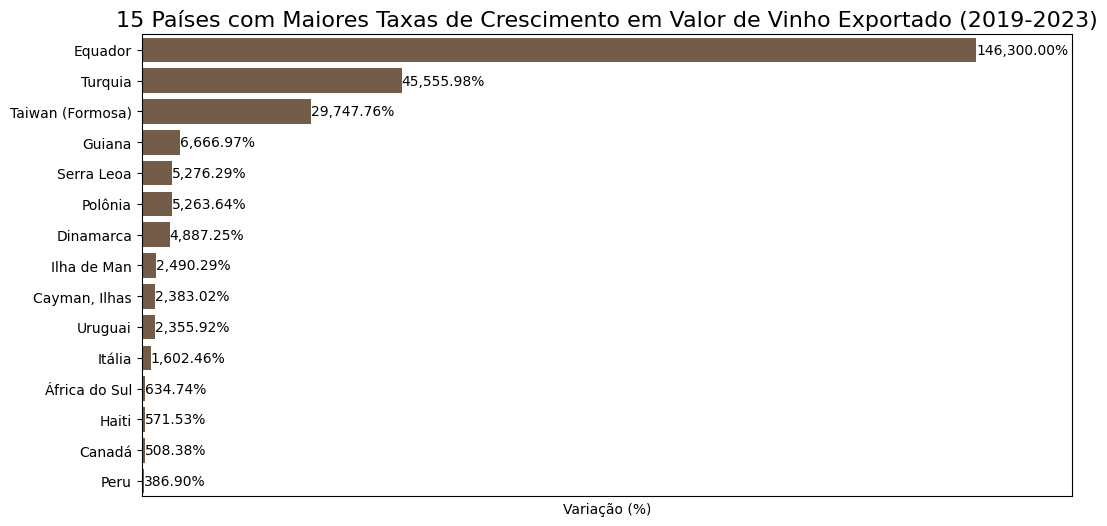

In [30]:
# Filtrar os dados para os anos de 2019 e 2023
df_2019_2023 = df_long[df_long['Ano'].isin([2019, 2023])]

# Somar o valor exportado por país para 2019 e 2023
df_pivot = df_2019_2023[df_2019_2023['Ano'].isin([2019, 2023])].pivot_table(
    index='País',
    columns='Ano',
    values='Valor ($)',
    aggfunc='sum'
)

# Substituir valores zero por NaN para evitar divisão por zero
df_pivot[2019] = df_pivot[2019].replace(0, np.nan)

# Calcular a variação percentual para cada país entre 2019 e 2023
df_pivot['Variação Valor (%)'] = ((df_pivot[2023] - df_pivot[2019]) / df_pivot[2019]) * 100

# Remover linhas com NaN (casos onde 2019 tinha valor zero)
df_pivot = df_pivot.dropna(subset=['Variação Valor (%)'])

# Ordenar os países pela variação de valor
top_15_valor = df_pivot.sort_values('Variação Valor (%)', ascending=False).head(15)

# Gráfico de variação de valor
plt.figure(figsize=(12, 6))
bar_plot = sns.barplot(data=top_15_valor, x='Variação Valor (%)', y=top_15_valor.index, color='#7A5C42')

# Adicionar título e rótulos
plt.title('15 Países com Maiores Taxas de Crescimento em Valor de Vinho Exportado (2019-2023)', fontsize=16)
plt.xlabel('Variação (%)')
plt.ylabel('')

# Adicionar valores de variação ao lado das barras, com ponto separando os milhares
for index, value in enumerate(top_15_valor['Variação Valor (%)']):
    bar_plot.text(value + 0.5, index, f'{value:,.2f}%', color='black', va='center')

# Remover os ticks do eixo X
plt.xticks([])

# Ajustar o layout para que tudo fique visível
plt.xlim(0,163000)
plt.show()


In [18]:
# Filtrar dados para os últimos 15 anos (2009-2023)
df_recent = df_long[df_long['Ano'] >= 2009]

# Somar a quantidade exportada por país
df_summary = df_recent.groupby('País').agg({'Valor ($)': 'sum'}).reset_index()

# Ordenar os dados pela quantidade exportada em ordem decrescente
df_summary = df_summary.sort_values('Valor ($)', ascending=False)

# Calcular o total exportado
total_quantity = df_summary['Valor ($)'].sum()

# Criar uma coluna com a porcentagem do total
df_summary['% do Total'] = (df_summary['Valor ($)'] / total_quantity) * 100

# Criar a coluna com a porcentagem acumulada
df_summary['% Acumulada'] = df_summary['% do Total'].cumsum()
df_summary.reset_index(inplace=True)

# Exibir os primeiros resultados
df_summary.head(10)

,index,País,Valor ($),% do Total,% Acumulada
0,100,Paraguai,42862206,37.450827,37.450827
1,110,Rússia,23151716,20.228798,57.679625
2,48,Estados Unidos,9309051,8.133778,65.813402
3,28,China,4903695,4.284601,70.098003
4,108,Reino Unido,4640935,4.055014,74.153017
5,47,Espanha,3805889,3.325393,77.478410
6,62,Haiti,3198849,2.794992,80.273403
7,101,Países Baixos,3012934,2.632549,82.905952
8,75,Japão,2257163,1.972195,84.878147
9,1,"Alemanha, República Democrática",2148277,1.877056,86.755202


In [19]:
# Filtrar dados para os últimos 15 anos (2009-2023)
df_recent = df_long[df_long['Ano'] >= 2009]

# Somar a quantidade exportada por país
df_summary = df_recent.groupby('País').agg({'Quantidade (kg)': 'sum'}).reset_index()

# Ordenar os dados pela quantidade exportada em ordem decrescente
df_summary = df_summary.sort_values('Quantidade (kg)', ascending=False)

# Calcular o total exportado
total_quantity = df_summary['Quantidade (kg)'].sum()

# Criar uma coluna com a porcentagem do total
df_summary['% do Total'] = (df_summary['Quantidade (kg)'] / total_quantity) * 100

# Criar a coluna com a porcentagem acumulada
df_summary['% Acumulada'] = df_summary['% do Total'].cumsum()

df_summary.reset_index(inplace=True)
# Exibir os primeiros resultados
df_summary.head(10)

,index,País,Quantidade (kg),% do Total,% Acumulada
0,110,Rússia,32822141,39.461548,39.461548
1,100,Paraguai,30803247,37.034263,76.495810
2,48,Estados Unidos,3349299,4.026810,80.522620
3,28,China,2574686,3.095505,83.618125
4,62,Haiti,2351228,2.826845,86.444970
5,47,Espanha,1990238,2.392832,88.837802
6,108,Reino Unido,1150780,1.383565,90.221367
7,131,Uruguai,1118688,1.344981,91.566348
8,75,Japão,972341,1.169030,92.735378
9,101,Países Baixos,897986,1.079635,93.815013


In [20]:
# Filtrar dados para os últimos 15 anos (2009-2023)
df_recent = df_long[df_long['Ano'] >= 2009]

# Agrupar por Ano para calcular os totais de Quantidade e Valor
total_por_ano = df_recent.groupby('Ano')[['Quantidade (kg)', 'Valor ($)']].sum().reset_index()

# Merging para adicionar os totais ao dataframe original
df_recent = df_recent.merge(total_por_ano, on='Ano', suffixes=('', '_Total'))

# Calcular a porcentagem de Quantidade e Valor em relação ao total
df_recent['Porcentagem_Quantidade'] = (df_recent['Quantidade (kg)'] / df_recent['Quantidade (kg)_Total']) * 100
df_recent['Porcentagem_Valor'] = (df_recent['Valor ($)'] / df_recent['Valor ($)_Total']) * 100

# Exibir as primeiras linhas do dataframe para verificar
df_recent.head()


,Id,País,Quantidade (kg),Valor ($),Ano,Quantidade (kg)_Total,Valor ($)_Total,Porcentagem_Quantidade,Porcentagem_Valor
0,1,Afeganistão,0,0,2009,25514198,8940988,0.000000,0.000000
1,2,África do Sul,0,0,2009,25514198,8940988,0.000000,0.000000
2,3,"Alemanha, República Democrática",225086,393482,2009,25514198,8940988,0.882199,4.400878
3,4,Angola,54786,84235,2009,25514198,8940988,0.214728,0.942122
4,5,Anguilla,0,0,2009,25514198,8940988,0.000000,0.000000


In [21]:
df_recent[df_recent['País'] == 'Paraguai']

,Id,País,Quantidade (kg),Valor ($),Ano,Quantidade (kg)_Total,Valor ($)_Total,Porcentagem_Quantidade,Porcentagem_Valor
103,104,Paraguai,486927,392087,2009,25514198,8940988,1.908455,4.385276
240,104,Paraguai,510989,449197,2010,1280574,2595303,39.903122,17.308075
377,104,Paraguai,240168,276281,2011,1214834,3615120,19.769615,7.642374
514,104,Paraguai,354824,428279,2012,5775376,5521293,6.143739,7.756861
651,104,Paraguai,481564,680828,2013,9149059,22744845,5.263536,2.993329
788,104,Paraguai,521847,908028,2014,2324029,7472795,22.454410,12.151116
925,104,Paraguai,495428,741370,2015,1198479,2769160,41.338063,26.772379
1062,104,Paraguai,985739,1655417,2016,1786549,4434704,55.175593,37.328692
1199,104,Paraguai,2393468,4274650,2017,2889572,7135607,82.831229,59.905906
1336,104,Paraguai,3234168,5494321,2018,3856162,7486063,83.870128,73.393999


In [22]:
df_recent[df_recent['País'] == 'Rússia']

,Id,País,Quantidade (kg),Valor ($),Ano,Quantidade (kg)_Total,Valor ($)_Total,Porcentagem_Quantidade,Porcentagem_Valor
112,113,Rússia,21912914,5732280,2009,25514198,8940988,85.885177,64.112378
249,113,Rússia,0,0,2010,1280574,2595303,0.000000,0.000000
386,113,Rússia,0,0,2011,1214834,3615120,0.000000,0.000000
523,113,Rússia,4528176,2103968,2012,5775376,5521293,78.404869,38.106436
660,113,Rússia,5893291,14795694,2013,9149059,22744845,64.414176,65.050758
797,113,Rússia,190656,61440,2014,2324029,7472795,8.203684,0.822182
934,113,Rússia,47664,18240,2015,1198479,2769160,3.977041,0.658683
1071,113,Rússia,0,0,2016,1786549,4434704,0.000000,0.000000
1208,113,Rússia,0,0,2017,2889572,7135607,0.000000,0.000000
1345,113,Rússia,0,0,2018,3856162,7486063,0.000000,0.000000


In [23]:
df_recent[df_recent['País'] == 'Estados Unidos']

,Id,País,Quantidade (kg),Valor ($),Ano,Quantidade (kg)_Total,Valor ($)_Total,Porcentagem_Quantidade,Porcentagem_Valor
50,51,Estados Unidos,372319,660066,2009,25514198,8940988,1.459262,7.382473
187,51,Estados Unidos,228968,478630,2010,1280574,2595303,17.880107,18.442163
324,51,Estados Unidos,306787,1030254,2011,1214834,3615120,25.253409,28.498473
461,51,Estados Unidos,146585,303986,2012,5775376,5521293,2.538103,5.505703
598,51,Estados Unidos,245368,786556,2013,9149059,22744845,2.681893,3.458173
735,51,Estados Unidos,222267,494216,2014,2324029,7472795,9.563865,6.613536
872,51,Estados Unidos,195896,524109,2015,1198479,2769160,16.345384,18.926642
1009,51,Estados Unidos,258072,687411,2016,1786549,4434704,14.445280,15.500719
1146,51,Estados Unidos,132688,1523699,2017,2889572,7135607,4.591960,21.353460
1283,51,Estados Unidos,169109,512519,2018,3856162,7486063,4.385423,6.846309


In [25]:
df_recent[df_recent['País'] == 'China']

,Id,País,Quantidade (kg),Valor ($),Ano,Quantidade (kg)_Total,Valor ($)_Total,Porcentagem_Quantidade,Porcentagem_Valor
30,31,China,1553416,482400,2009,25514198,8940988,6.088438,5.395377
167,31,China,795,2358,2010,1280574,2595303,0.062082,0.090856
304,31,China,54156,334867,2011,1214834,3615120,4.457893,9.262957
441,31,China,87905,642177,2012,5775376,5521293,1.522065,11.630917
578,31,China,40929,279956,2013,9149059,22744845,0.447357,1.230855
715,31,China,64040,455340,2014,2324029,7472795,2.755559,6.093302
852,31,China,47609,222866,2015,1198479,2769160,3.972452,8.048145
989,31,China,134106,499622,2016,1786549,4434704,7.506427,11.266186
1126,31,China,67594,266086,2017,2889572,7135607,2.339239,3.728989
1263,31,China,30835,126336,2018,3856162,7486063,0.799629,1.687616


In [26]:
df_recent[df_recent['País'] == 'Reino Unido']

,Id,País,Quantidade (kg),Valor ($),Ano,Quantidade (kg)_Total,Valor ($)_Total,Porcentagem_Quantidade,Porcentagem_Valor
110,111,Reino Unido,30092,68788,2009,25514198,8940988,0.117942,0.769356
247,111,Reino Unido,123624,295690,2010,1280574,2595303,9.653796,11.393275
384,111,Reino Unido,122629,285642,2011,1214834,3615120,10.094301,7.901314
521,111,Reino Unido,82937,334856,2012,5775376,5521293,1.436045,6.064811
658,111,Reino Unido,59161,305005,2013,9149059,22744845,0.646635,1.340985
795,111,Reino Unido,305807,1373747,2014,2324029,7472795,13.158485,18.383309
932,111,Reino Unido,68382,308407,2015,1198479,2769160,5.705732,11.137204
1069,111,Reino Unido,117044,536681,2016,1786549,4434704,6.551402,12.101845
1206,111,Reino Unido,60711,242883,2017,2889572,7135607,2.101038,3.403817
1343,111,Reino Unido,67708,296827,2018,3856162,7486063,1.755839,3.965061


In [27]:
df_recent[df_recent['País'] == 'Espanha']

,Id,País,Quantidade (kg),Valor ($),Ano,Quantidade (kg)_Total,Valor ($)_Total,Porcentagem_Quantidade,Porcentagem_Valor
49,50,Espanha,2181,4050,2009,25514198,8940988,0.008548,0.045297
186,50,Espanha,0,0,2010,1280574,2595303,0.000000,0.000000
323,50,Espanha,5206,24618,2011,1214834,3615120,0.428536,0.680973
460,50,Espanha,0,0,2012,5775376,5521293,0.000000,0.000000
597,50,Espanha,1972980,3748940,2013,9149059,22744845,21.564841,16.482592
734,50,Espanha,0,0,2014,2324029,7472795,0.000000,0.000000
871,50,Espanha,0,0,2015,1198479,2769160,0.000000,0.000000
1008,50,Espanha,0,0,2016,1786549,4434704,0.000000,0.000000
1145,50,Espanha,0,0,2017,2889572,7135607,0.000000,0.000000
1282,50,Espanha,6123,22631,2018,3856162,7486063,0.158785,0.302308


In [28]:
df_recent[df_recent['País'] == 'Haiti']

,Id,País,Quantidade (kg),Valor ($),Ano,Quantidade (kg)_Total,Valor ($)_Total,Porcentagem_Quantidade,Porcentagem_Valor
64,65,Haiti,4500,5863,2009,25514198,8940988,0.017637,0.065574
201,65,Haiti,2700,3750,2010,1280574,2595303,0.210843,0.144492
338,65,Haiti,0,0,2011,1214834,3615120,0.000000,0.000000
475,65,Haiti,0,0,2012,5775376,5521293,0.000000,0.000000
612,65,Haiti,0,0,2013,9149059,22744845,0.000000,0.000000
749,65,Haiti,0,0,2014,2324029,7472795,0.000000,0.000000
886,65,Haiti,0,0,2015,1198479,2769160,0.000000,0.000000
1023,65,Haiti,0,0,2016,1786549,4434704,0.000000,0.000000
1160,65,Haiti,0,0,2017,2889572,7135607,0.000000,0.000000
1297,65,Haiti,79500,144425,2018,3856162,7486063,2.061635,1.929252
